In [1]:
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import RidgeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_curve, auc
import matplotlib.pyplot as plt
import numpy as np
from imblearn.over_sampling import SMOTE
from sklearn.inspection import PartialDependenceDisplay
from sklearn.feature_selection import RFE

## Data Description

Oxygen saturation data (SpO2) for 100 obstructive sleep apnea (OSA) patients was extracted from the Sleep Heart Health Study, with continuous measurements for each patient over the course of a multi-hour sleep study. The SpO2 data for each patient was split into the different sleep stages (S1, S2, S3, and S5) identified during the study, and the mean, 25th percentile, and 75th percentile of SpO2 for each sleep stage were calculated to be used as the predictors. The outcome variable (categorical) was the diagnosis of cardiovascular disease in the OSA patients. 

In [2]:
file_path = 'patientSpO2.csv'
data = pd.read_csv(file_path)

X = data.drop(columns=['CVD_Outcome'])
y = data['CVD_Outcome']

# Impute NaN values with the mean of each column
imputer = SimpleImputer(strategy="mean")
X_imputed = imputer.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X_imputed, y, test_size=0.2, random_state=42, stratify=y)

## Logistic Regression <!-- Second largest -->

Accuracy: 0.75
Confusion Matrix:
 [[7 3]
 [2 8]]
Classification Report:
               precision    recall  f1-score   support

           0       0.78      0.70      0.74        10
           1       0.73      0.80      0.76        10

    accuracy                           0.75        20
   macro avg       0.75      0.75      0.75        20
weighted avg       0.75      0.75      0.75        20



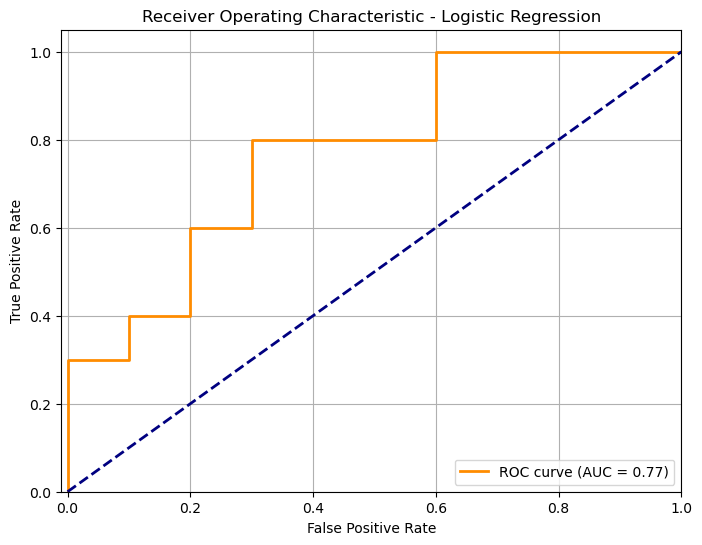

In [3]:
logistic_clf = LogisticRegression(random_state=42, max_iter=1000)
logistic_clf.fit(X_train, y_train)

y_pred = logistic_clf.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred)

print("Accuracy:", accuracy)
print("Confusion Matrix:\n", conf_matrix)
print("Classification Report:\n", class_report)

# Get predicted probabilities for the positive class
y_proba = logistic_clf.predict_proba(X_test)[:, 1]

# Compute ROC curve and AUC
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)

# Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (AUC = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([-0.01, 1.00])
plt.ylim([0.00, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic - Logistic Regression')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

In [4]:
# Extract feature importance (absolute coefficient values)
feature_importance = np.abs(logistic_clf.coef_[0])
feature_names = X.columns  # Ensure this matches your DataFrame
importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': feature_importance})
importance_df = importance_df.sort_values(by='Importance', ascending=False)

print("Feature Importance:")
print(importance_df)

# Recursive feature elimination
selector = RFE(estimator=logistic_clf, n_features_to_select=5, step=1)
selector.fit(X_train, y_train)

# Get selected features
selected_features = [feature for feature, support in zip(X.columns, selector.support_) if support]
print("Top 5 Selected Features:", selected_features)

Feature Importance:
           Feature  Importance
0   SpO2_median_S1    0.663706
6   SpO2_median_S3    0.420169
1     SpO2_25th_S1    0.346006
8     SpO2_75th_S3    0.327102
5     SpO2_75th_S2    0.302135
7     SpO2_25th_S3    0.292145
4     SpO2_25th_S2    0.282843
3   SpO2_median_S2    0.133356
2     SpO2_75th_S1    0.124018
10    SpO2_25th_S5    0.108837
9   SpO2_median_S5    0.085831
11    SpO2_75th_S5    0.049532
Top 5 Selected Features: ['SpO2_median_S1', 'SpO2_25th_S1', 'SpO2_75th_S2', 'SpO2_median_S3', 'SpO2_75th_S3']


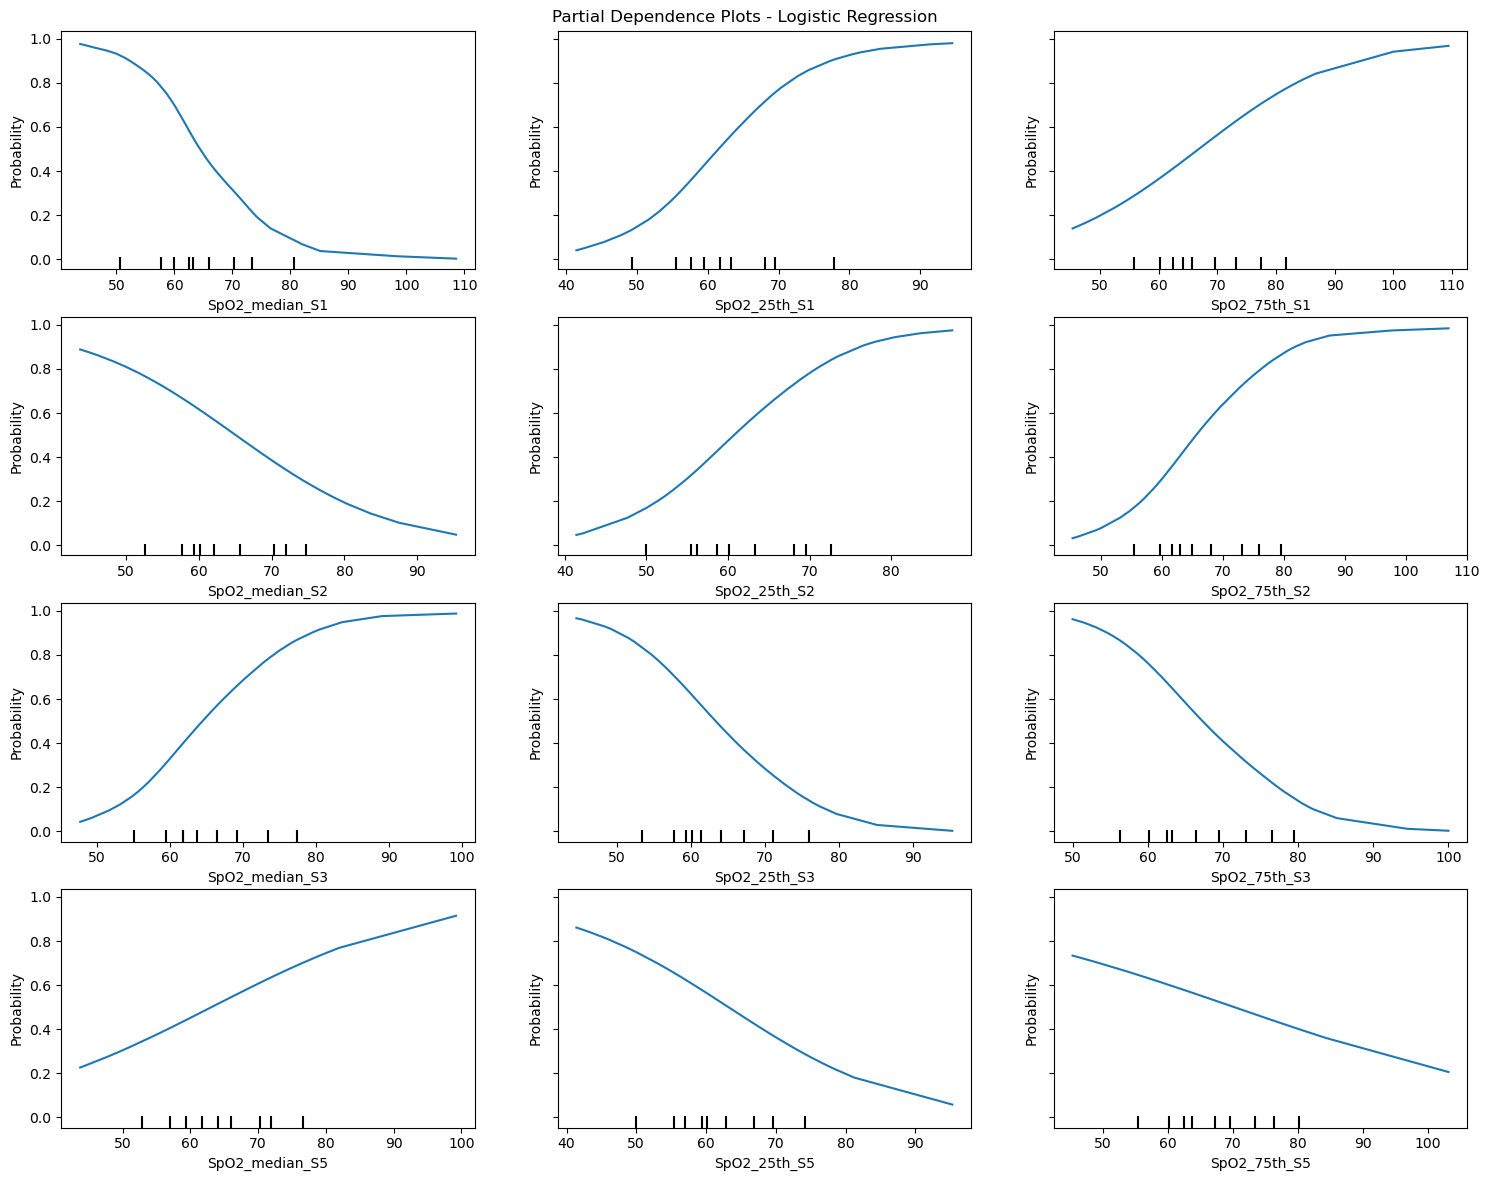

In [13]:
# Partial dependence plots for the original features
features_to_plot = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]  # Indices of features to analyze
fig, ax = plt.subplots(figsize=(15, 12))
display = PartialDependenceDisplay.from_estimator(logistic_clf, X_train, features=features_to_plot, feature_names=X.columns, ax=ax)

for axes in display.axes_.ravel():
    axes.set_ylabel("Probability")

plt.suptitle("Partial Dependence Plots - Logistic Regression")
plt.tight_layout()
plt.show()


## Interpretation 
1. **Performance Metrics**:
   Accuracy is 75%, meaning the model correctly predicts 75% of the outcomes.
   The model performs slightly better for predicting CVD_Outcome = 1, as indicated by higher recall (80%) compared to class 0 (70%). However, precision is slightly higher for CVD_Outcome = 0, showing better reliability when predicting control subjects.

2.  **ROC Curve and AUC**: 
   The model shows reasonably strong discriminatory power.
   The AUC value is 0.77, which indicates that the model has a good but not perfect ability to distinguish between the positive and negative classes.
An AUC of 0.77 means that, for this model, the probability of ranking a random positive instance higher than a random negative instance is 0.77.


3.  **Partial Dependence Plots**:
    Out of all predictors, SpO2 in sleep stage S5 show the weakest correlation to predictiong CVD_Outcome (last row).
    All other predictors have medium to strong predicting power, with a mix of positive and negative corrleation to CVD_Outcome = 1. Visually, SpO2_median_S1 has the steepest probability slope, playing a siginificant role in predicting CVD_Outcome and corroborating its importance score being the highest at 0.663. 

# Supplementary Models
## Random Forest 

Accuracy: 0.6
Confusion Matrix:
 [[7 3]
 [5 5]]
Classification Report:
               precision    recall  f1-score   support

           0       0.58      0.70      0.64        10
           1       0.62      0.50      0.56        10

    accuracy                           0.60        20
   macro avg       0.60      0.60      0.60        20
weighted avg       0.60      0.60      0.60        20



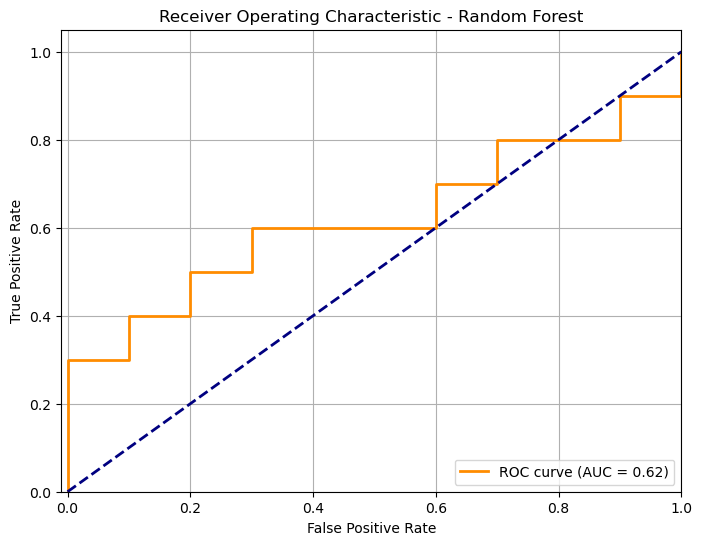

In [68]:
nforest = 1000
clf = RandomForestClassifier(random_state=42, n_estimators = nforest, max_depth = 10)
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)

report = classification_report(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)

accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred)

print("Accuracy:", accuracy)
print("Confusion Matrix:\n", conf_matrix)
print("Classification Report:\n", class_report)

# Get predicted probabilities for the positive class
y_proba = clf.predict_proba(X_test)[:, 1]

# Compute ROC curve and AUC
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)

# Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (AUC = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([-0.01, 1.00])
plt.ylim([0.00, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic - Random Forest')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

C:\Users\ngoct\anaconda3\Lib\site-packages\sklearn\model_selection\_validation.py:540: FitFailedWarning: 
75 fits failed out of a total of 225.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
6 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\ngoct\anaconda3\Lib\site-packages\sklearn\model_selection\_validation.py", line 888, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "C:\Users\ngoct\anaconda3\Lib\site-packages\sklearn\base.py", line 1466, in wrapper
    estimator._validate_params()
  File "C:\Users\ngoct\anaconda3\Lib\site-packages\sklearn\base.py", line 666, in _validate_params
    validate_parameter_constraints(
  File "C:\Users\ngoct\anaconda3\Lib\site-packages\

Best parameters found:  {'max_depth': 15, 'max_features': 'sqrt', 'n_estimators': 1000}
Best cross-validation accuracy: 0.57
Test Accuracy: 0.6
Confusion Matrix:
 [[7 3]
 [5 5]]
Classification Report:
               precision    recall  f1-score   support

           0       0.58      0.70      0.64        10
           1       0.62      0.50      0.56        10

    accuracy                           0.60        20
   macro avg       0.60      0.60      0.60        20
weighted avg       0.60      0.60      0.60        20



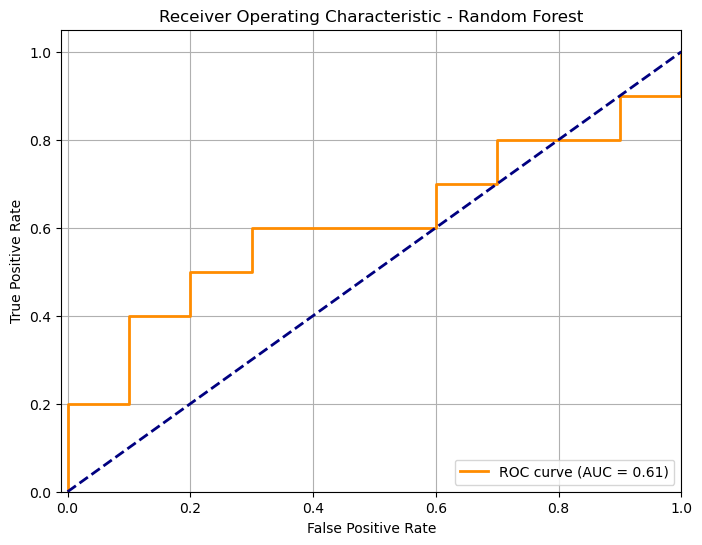

In [15]:
# Define the parameter grid for hyperparameter tuning
param_grid = {
    'n_estimators': [100, 500, 1000],
    'max_depth': [5, 10, 15, 20, None],
    'max_features': ['auto', 'sqrt', 'log2']
}

# Initialize the Random Forest classifier
clf = RandomForestClassifier(random_state=42)

# Use GridSearchCV for cross-validation and hyperparameter tuning
grid_search = GridSearchCV(
    estimator=clf,
    param_grid=param_grid,
    cv=5,
    n_jobs=-1,
    scoring='accuracy'
)

# Fit the model to find the best parameters
grid_search.fit(X_train, y_train)

# Output the best parameters
print("Best parameters found: ", grid_search.best_params_)
print("Best cross-validation accuracy: {:.2f}".format(grid_search.best_score_))

# Use the best estimator
best_clf = grid_search.best_estimator_

# Fit the model with the best parameters
best_clf.fit(X_train, y_train)

# Make predictions on the test set
y_pred = best_clf.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred)

print("Test Accuracy:", accuracy)
print("Confusion Matrix:\n", conf_matrix)
print("Classification Report:\n", class_report)

# Compute ROC curve and ROC area
y_proba = best_clf.predict_proba(X_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)

# Plot ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange',
         lw=2, label='ROC curve (AUC = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([-0.01, 1.00])
plt.ylim([0.00, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic - Random Forest')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()


## Logistic Regression and PCA


Accuracy: 0.6
Confusion Matrix:
 [[4 6]
 [2 8]]
Classification Report:
               precision    recall  f1-score   support

           0       0.67      0.40      0.50        10
           1       0.57      0.80      0.67        10

    accuracy                           0.60        20
   macro avg       0.62      0.60      0.58        20
weighted avg       0.62      0.60      0.58        20



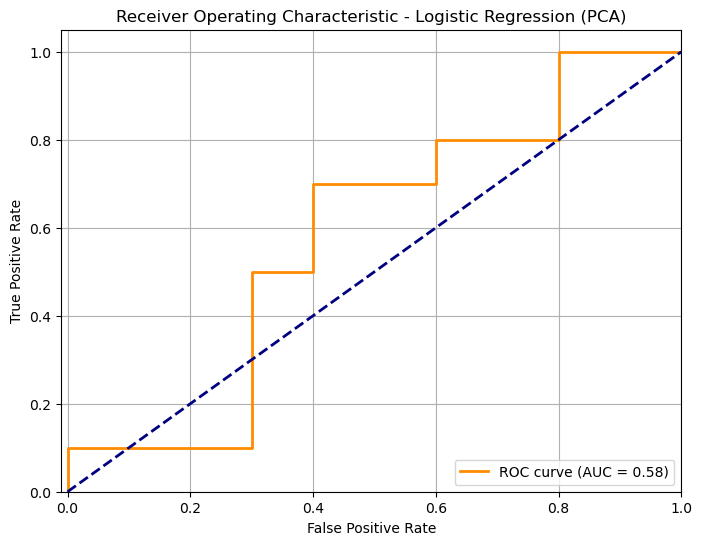

In [96]:
pca = PCA(n_components=5)  # Adjust the number of components as necessary
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

logistic_clf = LogisticRegression(random_state=42, max_iter=1000)
logistic_clf.fit(X_train_pca, y_train)

y_pred = logistic_clf.predict(X_test_pca)

accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred)

print("Accuracy:", accuracy)
print("Confusion Matrix:\n", conf_matrix)
print("Classification Report:\n", class_report)



# Get predicted probabilities for the positive class
y_proba = logistic_clf.predict_proba(X_test_pca)[:, 1]

# Compute ROC curve and AUC
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)

# Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (AUC = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([-0.01, 1.00])
plt.ylim([0.00, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic - Logistic Regression (PCA)')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

## Decision Tree 

Accuracy: 0.55
Confusion Matrix:
 [[6 4]
 [5 5]]
Classification Report:
               precision    recall  f1-score   support

           0       0.55      0.60      0.57        10
           1       0.56      0.50      0.53        10

    accuracy                           0.55        20
   macro avg       0.55      0.55      0.55        20
weighted avg       0.55      0.55      0.55        20



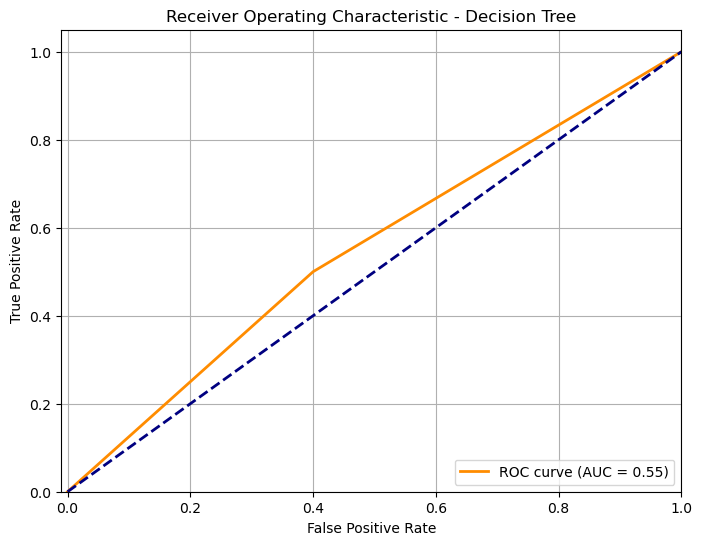

In [95]:
decision_tree_clf = DecisionTreeClassifier(random_state=42)
decision_tree_clf.fit(X_train, y_train)

y_pred = decision_tree_clf.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred)

print("Accuracy:", accuracy)
print("Confusion Matrix:\n", conf_matrix)
print("Classification Report:\n", class_report)


# Get predicted probabilities for the positive class
y_proba = decision_tree_clf.predict_proba(X_test)[:, 1]

# Compute ROC curve and AUC
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)

# Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (AUC = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([-0.01, 1.00])
plt.ylim([0.00, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic - Decision Tree')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()